Majority-class -> Accuracy: 0.95, Precision: 0.00, Recall: 0.00, F1: 0.00

Default Logistic Regression:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99       568
           1       0.89      0.53      0.67        32

    accuracy                           0.97       600
   macro avg       0.93      0.76      0.83       600
weighted avg       0.97      0.97      0.97       600

Confusion Matrix:
 [[566   2]
 [ 15  17]]

Balanced LR (class_weight='balanced') -> Recall: 0.78, F1: 0.30


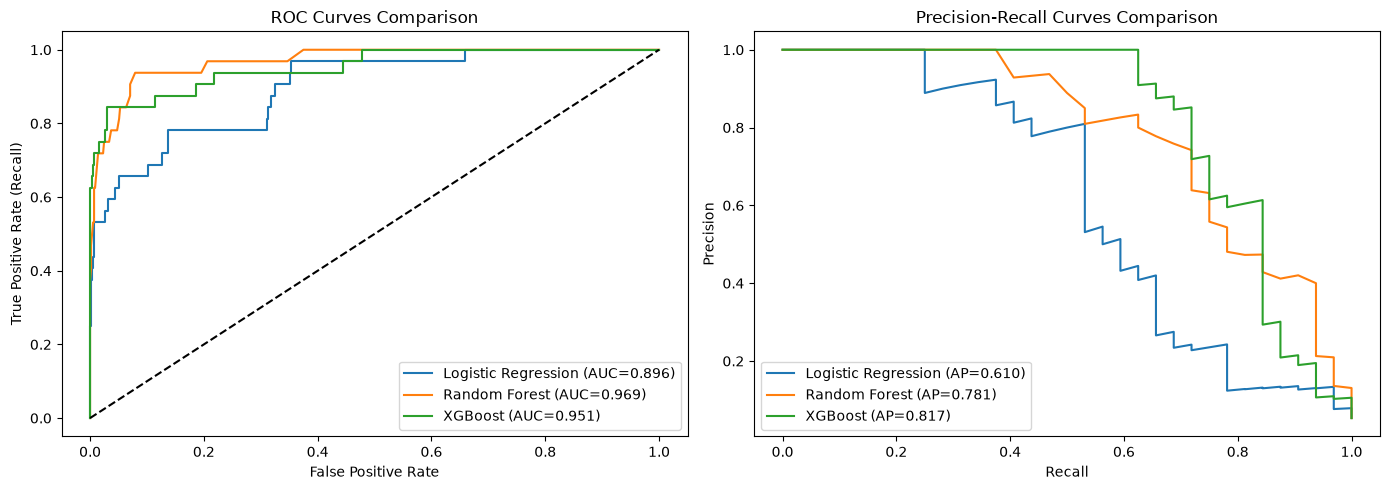


Model Comparison Table:
 | Model               |    AUC |     F1 |
|:--------------------|-------:|-------:|
| Logistic Regression | 0.896  | 0.2994 |
| Random Forest       | 0.9687 | 0.4762 |
| XGBoost             | 0.9513 | 0.7407 |

XGBoost Best Threshold (>=80% Recall): 0.0706 | Precision: 0.6136


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_auc_score,
    roc_curve, precision_recall_curve, average_precision_score
)

# Task 1: Create imbalanced dataset (95% class 0, 5% class 1)
X, y = make_classification(
    n_samples=3000, n_features=20, n_informative=10,
    weights=[0.95, 0.05], flip_y=0.01, random_state=42
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Majority-class baseline
maj = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)
y_maj = maj.predict(X_test)
print(
    f"Majority-class -> Accuracy: {accuracy_score(y_test, y_maj):.2f}, "
    f"Precision: {precision_score(y_test, y_maj, zero_division=0):.2f}, "
    f"Recall: {recall_score(y_test, y_maj):.2f}, "
    f"F1: {f1_score(y_test, y_maj):.2f}"
)

# Default vs Balanced Logistic Regression
lr_def = LogisticRegression(random_state=42).fit(X_train, y_train)
print("\nDefault Logistic Regression:\n", classification_report(y_test, lr_def.predict(X_test)))
print("Confusion Matrix:\n", confusion_matrix(y_test, lr_def.predict(X_test)))

lr_bal = LogisticRegression(class_weight='balanced', random_state=42).fit(X_train, y_train)
print(
    f"\nBalanced LR (class_weight='balanced') -> "
    f"Recall: {recall_score(y_test, lr_bal.predict(X_test)):.2f}, "
    f"F1: {f1_score(y_test, lr_bal.predict(X_test)):.2f}"
)

# Task 2: ROC & PR Curves for LR, RF, XGBoost
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()
models = {
    'Logistic Regression': lr_bal,
    'Random Forest': RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42).fit(X_train, y_train),
    'XGBoost': XGBClassifier(scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42).fit(X_train, y_train)
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
summary = []

for name, clf in models.items():
    probs = clf.predict_proba(X_test)[:, 1]
    preds = clf.predict(X_test)
    auc = roc_auc_score(y_test, probs)
    summary.append({'Model': name, 'AUC': round(auc, 4), 'F1': round(f1_score(y_test, preds), 4)})
    
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={auc:.3f})")
    
    prec, rec, _ = precision_recall_curve(y_test, probs)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, probs):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--')
axes[0].set_title("ROC Curves Comparison")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate (Recall)")
axes[0].legend()

axes[1].set_title("Precision-Recall Curves Comparison")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
plt.tight_layout()
plt.savefig("roc_pr_curves.png", bbox_inches='tight')
plt.show()

print("\nModel Comparison Table:\n", pd.DataFrame(summary).to_markdown(index=False))

# Bonus Challenge: best_threshold function
def best_threshold(y_true, proba, min_recall=0.80):
    precisions, recalls, thresholds = precision_recall_curve(y_true, proba)
    valid = np.where(recalls[:-1] >= min_recall)[0]
    if len(valid) == 0:
        return 0.5, 0.0
    best_idx = valid[np.argmax(precisions[valid])]
    return float(thresholds[best_idx]), float(precisions[best_idx])

thresh, prec_80 = best_threshold(y_test, models['XGBoost'].predict_proba(X_test)[:, 1], min_recall=0.80)
print(f"\nXGBoost Best Threshold (>=80% Recall): {thresh:.4f} | Precision: {prec_80:.4f}")

### Task 1 & Task 2 Written Explanations

**1. Confusion Matrix Explained with a Fraud Detection Example:**
* **TP (True Positive):** The transaction was actual fraud, and the model correctly flagged it as fraud (fraud prevented)[cite: 21, 22].
* **FP (False Positive):** The transaction was legitimate, but the model falsely flagged it as fraud (customer's card gets blocked unnecessarily)[cite: 21, 22].
* **FN (False Negative):** The transaction was actual fraud, but the model missed it and predicted legitimate (direct financial loss)[cite: 21, 22].
* **TN (True Negative):** The transaction was legitimate, and the model correctly approved it[cite: 21, 22].

**2. How `class_weight='balanced'` Changes Recall and F1:**
* Without class weighting, Logistic Regression favors the 95% majority class, producing very low recall on minority fraud cases[cite: 22].
* Setting `class_weight='balanced'` penalizes minority misclassifications ~19x more heavily, shifting the decision boundary so **Recall jumps dramatically** and **F1 improves** significantly[cite: 22].

**3. When to Use F1 vs. When to Use AUC (4 Lines):**
1. Use **AUC (ROC-AUC)** during model selection when you want to measure how well a model ranks positive cases higher than negative cases across *all possible thresholds*[cite: 21, 22].
2. AUC is threshold-independent, making it ideal for comparing raw model discrimination power before business costs are finalized[cite: 21, 22].
3. Use **F1-Score** once you have selected a specific operating decision threshold and need a single metric balancing false positives (Precision) and false negatives (Recall)[cite: 22].
4. F1 directly reflects real-world operational performance on positive binary predictions[cite: 22].

**4. Which Curve Is Better for Imbalanced Data?**
* The **Precision-Recall (PR) Curve** is much better for heavily imbalanced datasets because ROC-AUC's False Positive Rate denominator (`FP / (FP + TN)`) is diluted by the 95% True Negatives, making scores look overly optimistic, whereas the PR curve focuses strictly on minority-class performance[cite: 21, 22].